# Initialisation study, novel views, depth and PLY export

`scripts/train.py` trained three 7k-step models of the bonsai scene that differ **only in
their initial Gaussians** (same cameras, hyper-parameters, seed and 780x520 resolution):

| run | initial points |
|---|---|
| `colmap_7k` | 206k COLMAP SfM points |
| `random_7k` | 100k uniform random points |
| `da3_7k` | 206k points from Depth Anything 3 (unposed, feed-forward, Sim(3)-aligned) |

A fourth run, `colmap_15k`, uses the COLMAP initialisation with a 15k-step schedule
(densification over its full default window, steps 500-15000) as a longer-training reference.

This notebook loads their metrics (`projects/11_gaussian_splatting/results/*.json`) and
checkpoints (`runs/11_gaussian_splatting/*/ckpt.pt`) and:

1. compares test PSNR / SSIM / LPIPS, Gaussian count, training time and peak VRAM;
2. renders held-out views from each model side by side;
3. renders **depth** from the splats and back-projects it to a 3D point cloud (what a
   robot would use for mapping or collision checking);
4. flies a novel camera orbit that is not in the dataset (GIF in `assets/`);
5. checks the exported standard 3DGS `.ply` (viewable in SuperSplat or other web viewers);
6. shows the "own capture" path: SfM with `sfm_from_images.py` on 49 photos, then training.

**What you'll learn**: how to evaluate a radiance field honestly, what initialisation buys
you, how splats give dense depth, and what the exported file contains.

**Prerequisites**: notebooks 01-02, `make data-11_gaussian_splatting`, and the training runs
listed in the project README (`scripts/train.py`, about 3-4 minutes per 7k-step run).
Runtime: under a minute on an RTX 5060 Laptop GPU (8 GB).

## Setup

In [1]:
# --- Setup: imports, device, repo-relative paths, plot style ---
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from cvlab import viz
from cvlab.bench import benchmark
from cvlab.device import setup
from cvlab.io import assets_dir, data_dir, load_json, outputs_dir, project_dir, repo_root
from cvlab.pointcloud import depth_to_points, read_ply

PROJECT = "11_gaussian_splatting"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import splatkit as S  # noqa: E402

device = setup(seed=0)
viz.set_style()
RESULTS = project_dir(PROJECT) / "results"
RUNS = {"COLMAP": "colmap_7k", "random": "random_7k", "DA3": "da3_7k"}
runs = {k: load_json(RESULTS / f"{v}.json") for k, v in RUNS.items()}
long_run = load_json(RESULTS / "colmap_15k.json")  # longer-schedule reference (COLMAP init)
scene = S.load_colmap_scene(data_dir("mipnerf360", "bonsai"), images="images_4")
print({k: r["status"] for k, r in runs.items()}, "| hardware:", runs["COLMAP"]["hardware"]["gpu"])

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


{'COLMAP': 'ok', 'random': 'ok', 'DA3': 'ok'} | hardware: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. Final metrics

The protocol is the Mip-NeRF 360 / 3DGS one: render each of the 37 held-out views (every 8th
image) and average **PSNR** ($10\log_{10}(1/\mathrm{MSE})$, higher is better), **SSIM**
(local structure, higher is better) and **LPIPS** (a learned perceptual distance with AlexNet
features, lower is better) over the views. Training time excludes the periodic evaluation
passes. Peak VRAM is `torch.cuda.max_memory_allocated()` during training. The last row
is the 15k-step COLMAP run, for reference.

In [2]:
# --- Table of the final test metrics for the three initialisations ---
rows = []
for k, r in [*runs.items(), ("COLMAP, 15k steps", long_run)]:
    f = r["final"]
    rows.append({"init": k, "initial points": r["n_init"], "final Gaussians": f["n_gaussians"],
                 "PSNR [dB]": f["psnr"], "SSIM": f["ssim"], "LPIPS": f["lpips"],
                 "train time [s]": f["train_time_s"], "peak VRAM [MiB]": f["peak_vram_mb"],
                 "render [FPS]": f["render_fps"], "PLY [MiB]": f["ply_mib"]})
table = pd.DataFrame(rows).set_index("init")
metrics = table.loc[list(runs)]  # the three 7k-step runs of the initialisation study
table.style.format({"PSNR [dB]": "{:.2f}", "SSIM": "{:.4f}", "LPIPS": "{:.4f}",
                      "train time [s]": "{:.0f}", "peak VRAM [MiB]": "{:.0f}",
                      "render [FPS]": "{:.0f}", "PLY [MiB]": "{:.0f}",
                      "initial points": "{:,}", "final Gaussians": "{:,}"})

,initial points,final Gaussians,PSNR [dB],SSIM,LPIPS,train time [s],peak VRAM [MiB],render [FPS],PLY [MiB]
init,,,,,,,,,
COLMAP,"206,613","1,218,190",30.73,0.9451,0.0706,222,1845,118,274
random,"100,000","1,102,785",27.13,0.8751,0.1614,173,1672,145,248
DA3,"206,613","1,360,050",29.45,0.9243,0.0841,232,2060,103,306
"COLMAP, 15k steps","206,613","1,555,965",31.44,0.9416,0.0656,621,2351,82,350


## 2. Held-out views side by side

Each model renders the same two test cameras (never seen in training). PSNR per image is
in the titles.

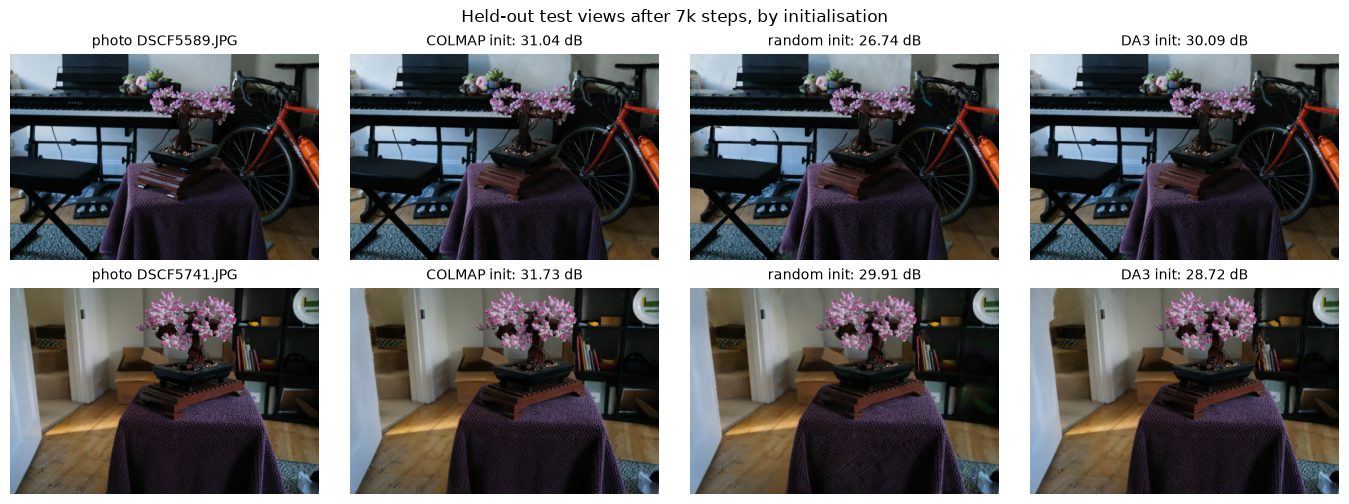

In [3]:
# --- Load the three checkpoints and render two test views each ---
models = {k: S.load_checkpoint(repo_root() / r["checkpoint"], device=device)[0]
          for k, r in runs.items()}
images = S.images_to_tensors(scene.load_images())
views = [int(scene.test_idx[3]), int(scene.test_idx[22])]
ev = {k: S.evaluate(m, scene, images, views, 3, device, lpips=False, return_renders=True)
      for k, m in models.items()}
tiles, titles = [], []
for j, v in enumerate(views):
    tiles.append(images[v].numpy())
    titles.append(f"photo {scene.names[v]}")
    for k in models:
        tiles.append(ev[k]["renders"][j])
        titles.append(f"{k} init: {ev[k]['per_image'][j]['psnr']:.2f} dB")
fig = viz.show_images(tiles, titles, ncols=4, size=3.4)
fig.suptitle("Held-out test views after 7k steps, by initialisation")
viz.savefig(fig, PROJECT, "test_views_by_init")
plt.show()

Whole-image PSNR is dominated by the well-observed bonsai in the centre. Zooming into the
top-left quarter of the first view (the room behind the plant) shows where the initialisations
really differ: background regions are seen by fewer training views and contain few SfM points,
so a Gaussian that was never seeded there must be created by densification.

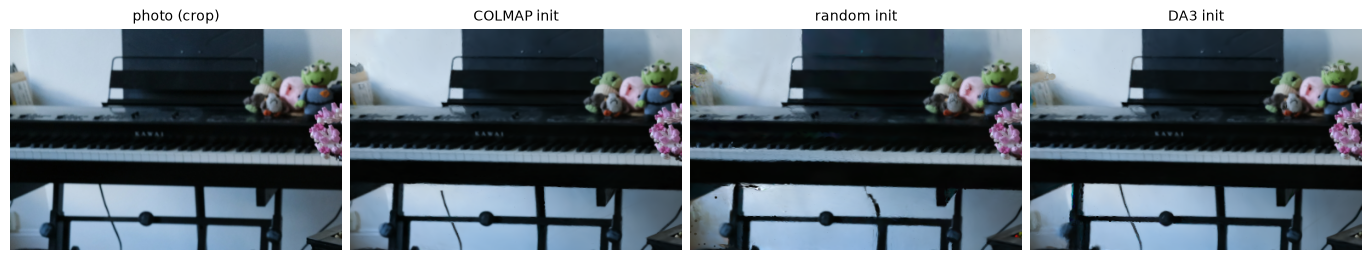

In [4]:
# --- Zoom: top-left quarter (background) of the first test view ---
# Background regions are seen by fewer training views and have few SfM points.
h, w = scene.heights[views[0]], scene.widths[views[0]]
crop = (slice(0, h // 2), slice(0, w // 2))
tiles = [images[views[0]].numpy()[crop]] + [ev[k]["renders"][0][crop] for k in models]
fig = viz.show_images(tiles, ["photo (crop)"] + [f"{k} init" for k in models], ncols=4, size=3.4)
plt.show()

## 3. Per-view quality

A mean can hide failures. The plot shows the PSNR of every test view for each
initialisation; the dips are the hardest viewpoints, and the gap between the curves
shows whether an initialisation is worse everywhere or only on some views.

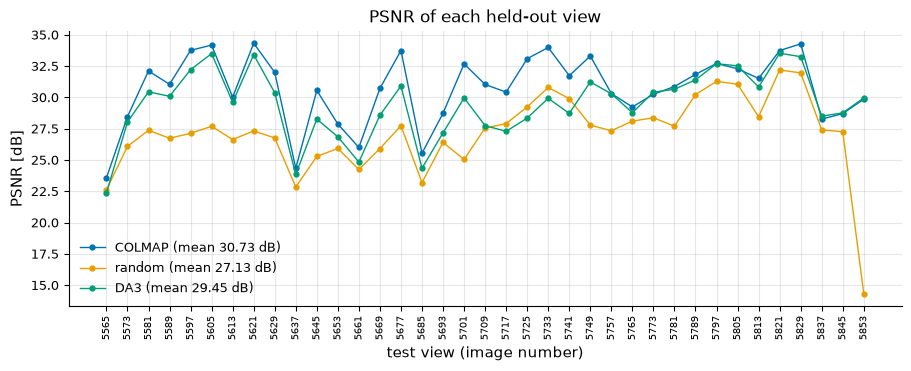

In [5]:
# --- Per-test-view PSNR for each initialisation ---
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (k, r) in enumerate(runs.items()):
    p = [x["psnr"] for x in r["per_image"]]
    ax.plot(range(len(p)), p, "o-", ms=3.5, lw=1, color=viz.color(i, unit=True),
            label=f"{k} (mean {np.mean(p):.2f} dB)")
ax.set_xticks(range(len(runs["COLMAP"]["test_names"])))
ax.set_xticklabels([n.split(".")[0][-4:] for n in runs["COLMAP"]["test_names"]], rotation=90,
                   fontsize=7)
ax.set_xlabel("test view (image number)")
ax.set_ylabel("PSNR [dB]")
ax.set_title("PSNR of each held-out view")
ax.legend()
plt.show()

## 4. Depth from splats: a dense 3D map

With `render_mode="RGB+ED"` the rasteriser also returns the **expected depth**
$\hat D=\sum_i z_i\alpha_iT_i/\sum_i\alpha_iT_i$ per pixel. Back-projecting it with the
intrinsics, $\mathbf X_c = \hat D\,K^{-1}[u,v,1]^\top$, and moving the points to the world
with $T_{wc}$ gives a dense, coloured point cloud from any viewpoint, including views that
were never photographed. Pixels with low accumulated opacity ($1-T<0.5$) are masked, since
their depth is a blend of the background and nothing.

Depth is in COLMAP units. COLMAP's scale is arbitrary, so for metric robotics use the model
must be scaled, e.g. with a known distance, an AprilTag (project 07) or a metric depth
model (project 08).

101,057 points from one 780x520 render (stride 2), depth range [ 4.05 17.91] COLMAP units


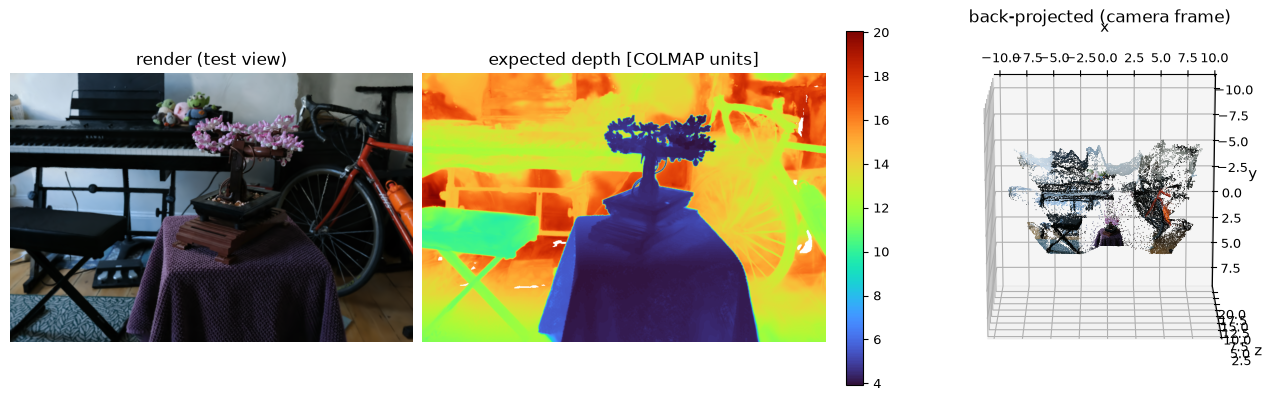

In [6]:
# --- Render RGB + expected depth from a test view and lift it to 3D ---
m = models["COLMAP"]
v = views[0]
vm = torch.as_tensor(scene.w2c[v:v + 1], dtype=torch.float32, device=device)
Kv = torch.as_tensor(scene.K[v:v + 1], dtype=torch.float32, device=device)
with torch.no_grad():
    out, alpha, _ = S.render(m, vm, Kv, scene.widths[v], scene.heights[v], 3, render_mode="RGB+ED")
rgb = out[0, ..., :3].clamp(0, 1).cpu().numpy()
depth = out[0, ..., 3].cpu().numpy()
acc = alpha[0, ..., 0].cpu().numpy()
pts_c, cols = depth_to_points(depth, scene.K[v], rgb=rgb, mask=acc > 0.5, stride=2)
c2w_v = scene.c2w[v]
pts_w = pts_c @ c2w_v[:3, :3].T + c2w_v[:3, 3]  # camera -> world (COLMAP frame)
print(f"{len(pts_w):,} points from one {scene.widths[v]}x{scene.heights[v]} render "
      f"(stride 2), depth range {np.percentile(depth[acc > 0.5], [2, 98]).round(2)} COLMAP units")

fig = plt.figure(figsize=(13, 3.9))
ax = fig.add_subplot(1, 3, 1)
ax.imshow(rgb)
ax.set_title("render (test view)")
ax.axis("off")
ax = fig.add_subplot(1, 3, 2)
im = ax.imshow(np.where(acc > 0.5, depth, np.nan), cmap="turbo")
ax.set_title("expected depth [COLMAP units]")
ax.axis("off")
fig.colorbar(im, ax=ax, fraction=0.046)
ax = fig.add_subplot(1, 3, 3, projection="3d")
viz.plot_point_cloud(pts_c, cols, ax=ax, max_points=40_000, size=0.4, elev=-75, azim=-90)
ax.set_title("back-projected (camera frame)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
viz.savefig(fig, PROJECT, "depth_render")
plt.show()

## 5. A novel camera path

The orbit is built from the capture geometry (notebook 02): a circle around the look-at
centre at the mean camera height and radius, with the camera always looking at the centre
(`look_at`, OpenCV axes). None of these 60 poses is in the dataset. Rendering is timed with
CUDA synchronisation (`cvlab.bench.benchmark`).

orbit GIF: assets/11_gaussian_splatting/orbit.gif (0.79 MB) | render 8.14 ms/frame = 123 FPS at 780x520


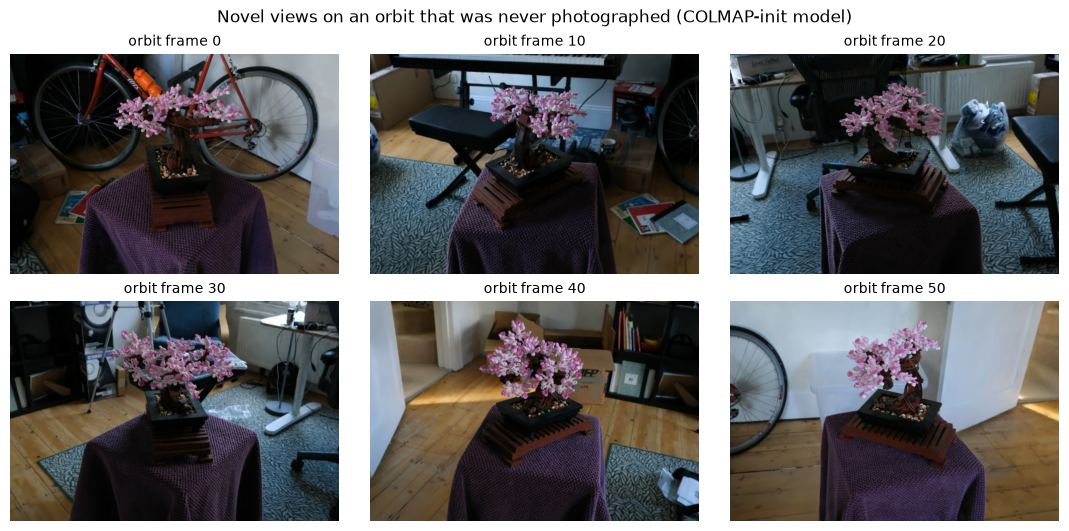

In [7]:
# --- Render a 60-frame orbit, time it and save a GIF + thumbnail for the README ---
orbit = S.orbit_path(scene, n_frames=60)
Kq = torch.as_tensor(scene.K[0:1], dtype=torch.float32, device=device)
W0, H0 = int(scene.widths[0]), int(scene.heights[0])
frames = []
with torch.no_grad():
    for T in orbit:
        vmq = torch.as_tensor(T[None], dtype=torch.float32, device=device)
        o, _, _ = S.render(m, vmq, Kq, W0, H0, 3)
        frames.append((o[0].clamp(0, 1).cpu().numpy() * 255).astype(np.uint8))
    vm0 = torch.as_tensor(orbit[:1], dtype=torch.float32, device=device)
    speed = benchmark(lambda: S.render(m, vm0, Kq, W0, H0, 3), warmup=5, iters=50)
gif = viz.save_gif(frames, assets_dir(PROJECT) / "orbit.gif", fps=12, max_side=360)
print(f"orbit GIF: {gif.relative_to(repo_root())} ({gif.stat().st_size / 1e6:.2f} MB) | "
      f"render {speed['mean_ms']:.2f} ms/frame = {speed['fps']:.0f} FPS at {W0}x{H0}")
fig = viz.show_images(frames[::10], [f"orbit frame {i}" for i in range(0, 60, 10)], ncols=3,
                      size=3.6)
fig.suptitle("Novel views on an orbit that was never photographed (COLMAP-init model)")
plt.show()
thumb = plt.figure(figsize=(3.4, 3.4 * H0 / W0))
ax = thumb.add_axes([0, 0, 1, 1])
ax.imshow(frames[8])
ax.axis("off")
viz.savefig(thumb, PROJECT, "thumb")
plt.close(thumb)

## 6. The exported `.ply`

`train.py` wrote each model with `gsplat.export_splats` in the layout of the original 3DGS
code, which web viewers such as SuperSplat, antimatter15/splat and PlayCanvas read. Per Gaussian:
position `x y z`, DC colour `f_dc_0..2`, 45 higher-order SH coefficients `f_rest_*`
(channel-major), `opacity` as a logit, `scale_0..2` as logs, and the quaternion `rot_0..3`
(wxyz). That is 59 float32 values = 236 bytes per Gaussian (the original code also writes three
unused normal fields `nx ny nz`; gsplat's exporter leaves them out). The cell reads the file
back and checks it against the checkpoint.

In [8]:
# --- Read the exported PLY back and compare with the checkpoint ---
ply_path = outputs_dir(PROJECT) / "colmap_7k.ply"
ply = read_ply(ply_path)
props = [k for k in ply if k not in ("points", "colors", "normals")]
same_xyz = np.abs(ply["points"] - m["means"].detach().cpu().numpy()).max()
same_opa = np.abs(ply["opacity"] - m["opacities"].detach().cpu().numpy()).max()
print(f"{ply_path.relative_to(repo_root())}: {len(ply['points']):,} vertices, "
      f"{len(props)} float properties, {ply_path.stat().st_size / 2**20:.1f} MiB")
print("properties:", " ".join(props[:8]), "...", " ".join(props[-8:]))
print(f"max |PLY - checkpoint|: xyz {same_xyz:.1e}, opacity logit {same_opa:.1e}")

outputs/11_gaussian_splatting/colmap_7k.ply: 1,218,190 vertices, 59 float properties, 274.2 MiB
properties: x y z f_dc_0 f_dc_1 f_dc_2 f_rest_0 f_rest_1 ... opacity scale_0 scale_1 scale_2 rot_0 rot_1 rot_2 rot_3
max |PLY - checkpoint|: xyz 0.0e+00, opacity logit 0.0e+00


## 7. Your own capture: SfM with pycolmap, then train

`scripts/sfm_from_images.py` runs SIFT, exhaustive matching, incremental mapping and
undistortion (CPU, official pycolmap) on a folder of photos or on frames sampled from a
video. Here it was run on every 6th bonsai photo (49 images at 780x520; none of the
dataset's COLMAP data is used), and `train.py` trained 3000 steps on its output. The
numbers are not comparable with the runs above: there are 6x fewer training images
(42 train / 7 test), a different SfM model with its own undistorted camera, and
3000 instead of 7000 steps.

In [9]:
# --- Results of the "own capture" path (sfm_from_images.py -> train.py) ---
sfm = load_json(data_dir("bonsai_sfm_demo") / "sfm_summary.json")
demo = load_json(RESULTS / "sfm_demo_3k.json")
pd.Series({
    "SfM: registered / input images": f"{sfm['n_registered']} / {sfm['n_frames']}",
    "SfM: 3D points": f"{sfm['n_points']:,}",
    "SfM: mean reprojection error [px]": round(sfm["mean_reprojection_error_px"], 3),
    "SfM: total CPU time [s]": round(sum(sfm["timings_s"].values()), 1),
    "camera after undistortion": f"{sfm['camera_model']} {sfm['image_size'][0]}x{sfm['image_size'][1]}",
    "train / test views": f"{demo['n_train']} / {demo['n_test']}",
    "steps": demo["config"]["steps"],
    "test PSNR [dB]": round(demo["final"]["psnr"], 2),
    "test SSIM": round(demo["final"]["ssim"], 4),
    "Gaussians": f"{demo['final']['n_gaussians']:,}",
    "train time [s]": round(demo["final"]["train_time_s"], 1),
    "peak VRAM [MiB]": round(demo["final"]["peak_vram_mb"]),
}, name="own-capture path (49 photos)").to_frame()

,own-capture path (49 photos)
SfM: registered / input images,49 / 49
SfM: 3D points,"12,868"
SfM: mean reprojection error [px],0.304
SfM: total CPU time [s],37.5
camera after undistortion,PINHOLE 782x521
train / test views,42 / 7
steps,3000
test PSNR [dB],21.7
test SSIM,0.7517
Gaussians,"540,877"


## Results

Training curves of the three runs: test PSNR every 1000 steps, the number of Gaussians
(densification from step 500, opacity resets at 3000 and 6000), and the smoothed training
loss. The dashed grey line is the 15k-step COLMAP run.

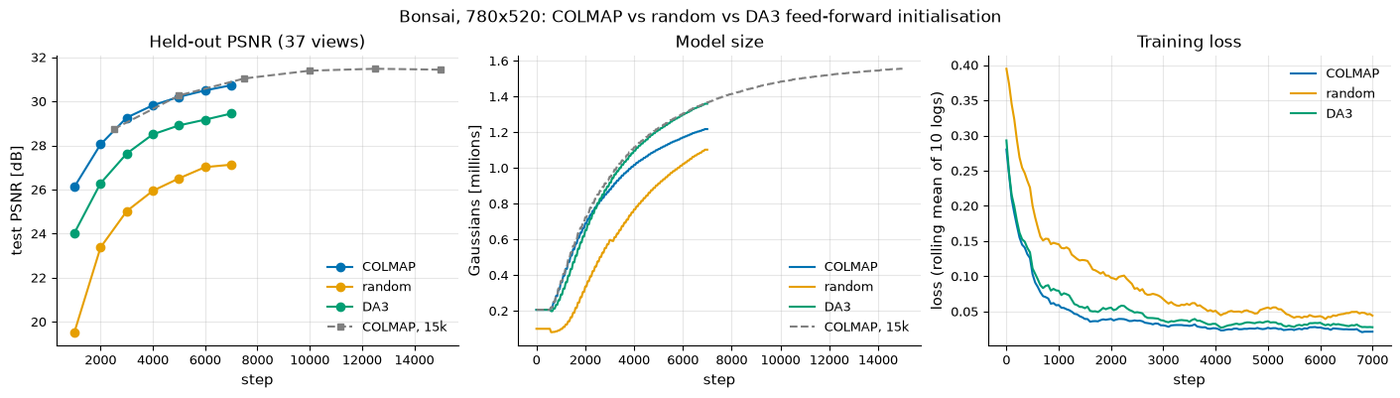

In [10]:
# --- Figure: training curves by initialisation (saved for the README) ---
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for i, (k, r) in enumerate(runs.items()):
    c = viz.color(i, unit=True)
    e = pd.DataFrame(r["eval_history"])
    hh = pd.DataFrame(r["history"])
    axes[0].plot(e["step"], e["psnr"], "o-", color=c, label=k)
    axes[1].plot(hh["step"], hh["n_gaussians"] / 1e6, color=c, label=k)
    axes[2].plot(hh["step"], hh["loss"].rolling(10, min_periods=1).mean(), color=c, label=k)
e15, h15 = pd.DataFrame(long_run["eval_history"]), pd.DataFrame(long_run["history"])
axes[0].plot(e15["step"], e15["psnr"], "s--", color="0.5", ms=4, label="COLMAP, 15k")
axes[1].plot(h15["step"], h15["n_gaussians"] / 1e6, "--", color="0.5", label="COLMAP, 15k")
axes[0].set_ylabel("test PSNR [dB]")
axes[0].set_title("Held-out PSNR (37 views)")
axes[1].set_ylabel("Gaussians [millions]")
axes[1].set_title("Model size")
axes[2].set_ylabel("loss (rolling mean of 10 logs)")
axes[2].set_title("Training loss")
for ax in axes:
    ax.set_xlabel("step")
    ax.legend()
fig.suptitle("Bonsai, 780x520: COLMAP vs random vs DA3 feed-forward initialisation")
viz.savefig(fig, PROJECT, "init_comparison_curves")
plt.show()

The bar charts put the final numbers of the three 7k-step runs side by side: quality
(PSNR, SSIM, LPIPS) and cost (training time, peak VRAM). The y-axes of PSNR and SSIM do not
start at zero, so read the bar labels for the actual gaps.

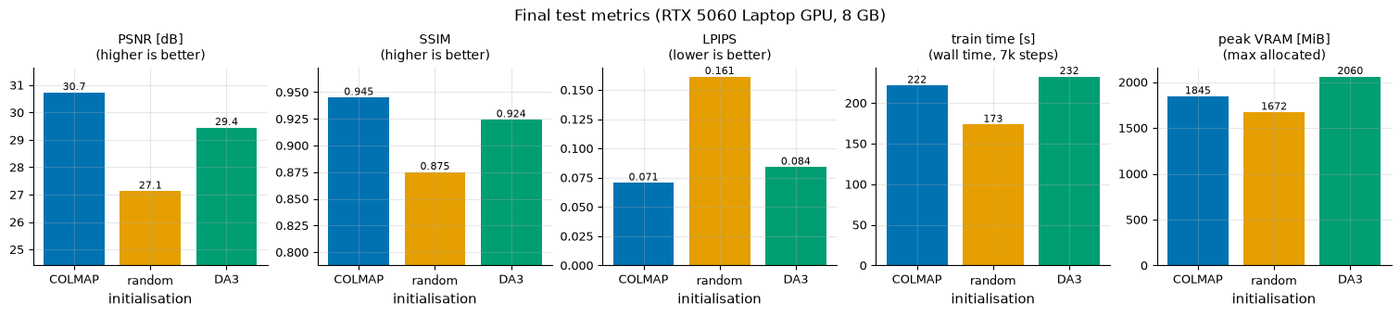

In [11]:
# --- Figure: final metrics, cost and speed by initialisation ---
fig, axes = plt.subplots(1, 5, figsize=(15, 3.3))
keys = [("PSNR [dB]", "higher is better"), ("SSIM", "higher is better"),
        ("LPIPS", "lower is better"), ("train time [s]", "wall time, 7k steps"),
        ("peak VRAM [MiB]", "max allocated")]
for ax, (col, sub) in zip(axes, keys, strict=True):
    vals = metrics[col].to_numpy()
    bars = ax.bar(metrics.index, vals, color=[viz.color(i, unit=True) for i in range(3)])
    ax.bar_label(bars, fmt="%.3f" if col in ("SSIM", "LPIPS") else "%.1f" if "PSNR" in col
                 else "%.0f", fontsize=8)
    ax.set_title(f"{col}\n({sub})", fontsize=10)
    lo = vals.min()
    if col in ("PSNR [dB]", "SSIM"):
        ax.set_ylim(lo * 0.9, vals.max() * 1.03)
    ax.set_xlabel("initialisation")
fig.suptitle("Final test metrics (RTX 5060 Laptop GPU, 8 GB)")
viz.savefig(fig, PROJECT, "init_comparison_metrics")
plt.show()

The summary table collects every training run of this project, including the 15k-step
reference and the own-capture demo, plus the orbit rendering speed measured above. It is
also written to `results/summary.csv`, which the README table is copied from.

In [12]:
# --- Summary table of all measured runs (also saved as results/summary.csv) ---
summary = table.copy()
summary.loc["own capture (49 photos, 3k steps)"] = pd.Series({
    "initial points": demo["n_init"], "final Gaussians": demo["final"]["n_gaussians"],
    "PSNR [dB]": demo["final"]["psnr"], "SSIM": demo["final"]["ssim"],
    "LPIPS": demo["final"]["lpips"], "train time [s]": demo["final"]["train_time_s"],
    "peak VRAM [MiB]": demo["final"]["peak_vram_mb"], "render [FPS]": demo["final"]["render_fps"],
    "PLY [MiB]": demo["final"]["ply_mib"]})
summary["orbit render [FPS]"] = [speed["fps"]] + [None] * (len(summary) - 1)
summary.round(4).to_csv(RESULTS / "summary.csv")
summary.round({"PSNR [dB]": 2, "SSIM": 4, "LPIPS": 4, "train time [s]": 0, "peak VRAM [MiB]": 0,
               "render [FPS]": 0, "PLY [MiB]": 1, "orbit render [FPS]": 0})

,initial points,final Gaussians,PSNR [dB],SSIM,LPIPS,train time [s],peak VRAM [MiB],render [FPS],PLY [MiB],orbit render [FPS]
init,,,,,,,,,,
COLMAP,206613,1218190,30.73,0.9451,0.0706,222.0,1845.0,118.0,274.2,123.0
random,100000,1102785,27.13,0.8751,0.1614,173.0,1672.0,145.0,248.2,NaN
DA3,206613,1360050,29.45,0.9243,0.0841,232.0,2060.0,103.0,306.1,NaN
"COLMAP, 15k steps",206613,1555965,31.44,0.9416,0.0656,621.0,2351.0,82.0,350.2,NaN
"own capture (49 photos, 3k steps)",12868,540877,21.70,0.7517,0.2883,42.0,826.0,260.0,121.7,NaN


**Takeaways**

- **Initialisation matters.** With identical cameras, hyper-parameters and 7k steps, the
  COLMAP-initialised model reaches 30.73 dB PSNR / 0.9451 SSIM /
  0.0706 LPIPS on the 37 held-out views, the DA3 feed-forward initialisation
  29.45 dB (-1.28 dB) and the random one 27.13 dB
  (-3.60 dB). The training curves show the random run is behind at
  every evaluation step, not just slower to start.
- **Feed-forward geometry is a usable substitute for SfM points.** DA3 needed
  2.1 s of GPU time on 32 unposed images and closes most of the gap
  between random and COLMAP points. Be careful with the claim, though: this run still
  trained with the **COLMAP camera poses**; only the initial points came from DA3. A fully
  SfM-free pipeline would also have to use DA3's poses (median rotation error
  1.49 deg, centre RMSE 2.56% of the
  scene scale after Sim(3) alignment), which was not tested here.
- **A noisier initialisation ends with more Gaussians.** The DA3 run finished with
  1,360,050 Gaussians vs 1,218,190 for COLMAP, and so needed more VRAM
  (2060 vs 1845 MiB) and rendered slower
  (103 vs 118 FPS).
- **Longer training helps, with diminishing returns.** 15k steps from the COLMAP points
  reached 31.44 dB (+0.71 dB over 7k) and LPIPS
  0.0656 (-0.0050), while SSIM moved by
  -0.0035: the metrics do not always agree. It cost
  10.3 min instead of 3.7 min and
  1,555,965 Gaussians. Everything here fits easily in 8 GB at 780x520
  (peak 2351 MiB).
- **Capture density dominates.** The own-capture path (49 photos, 42 for training, 3k steps)
  reached only 21.70 dB. With 6x fewer photos every surface is seen by fewer
  cameras and each test view is farther from its nearest training view: for a quick phone
  capture, the number and spacing of the photos limit quality more than the trainer does.
- Splat renders give dense, view-consistent depth (section 4) at 118 FPS for
  the 7k COLMAP model, but in COLMAP's arbitrary units: robotics use needs a metric scale.

## Exercises

Solutions: `projects/11_gaussian_splatting/solutions/ex03_novel_views.py`.

**Exercise 1: how many Gaussians do you really need?** Prune the COLMAP-init model by
opacity: keep Gaussians with $\sigma(\text{logit}) > \tau$ for $\tau\in\{0.01, 0.05, 0.1,
0.2, 0.5\}$, re-evaluate test PSNR and plot PSNR against the number of Gaussians (and the
PLY size at 236 bytes per Gaussian). Where does quality start to drop?

In [13]:
# --- Exercise 1: opacity pruning vs quality ---
# TODO: for each tau, build a ParameterDict with splats[k][keep] for every key, then call
# S.evaluate(pruned, scene, images, scene.test_idx, 3, device, lpips=False)["psnr"].

**Exercise 2: fuse rendered depth into a map.** Render RGB+ED from 8 test cameras, back-project
each depth map (mask `alpha > 0.5`), transform to the world frame, merge,
voxel-downsample (`cvlab.pointcloud.voxel_downsample`, voxel = 1% of the scene scale) and
write a PLY to `outputs/11_gaussian_splatting/`. How many points remain, and how does the
fused cloud compare with the COLMAP sparse points?

In [14]:
# --- Exercise 2: multi-view depth fusion from splat renders ---
# TODO: loop over scene.test_idx[:8], reuse the depth-to-world code of section 4,
# np.concatenate, voxel_downsample and cvlab.pointcloud.write_ply.